In [1]:
import numpy as np
import matplotlib.pyplot as plt
from schedule_utils import range_finder_general
from skyfield.api import load, EarthSatellite, wgs84
from pc_utils import rect, open_vdif, iq_conversion, pc_and_spectrogram, plotter
from scipy.ndimage import shift

### Intelsat 37E

In [2]:
tle_1 = '1 42950U 17059A   26281.09300963 -.00000156  00000-0  00000-0 0  9994'
tle_2 = '2 42950   0.0202 233.9637 0002879 328.8605 189.3995  1.00270430 33194'
tle_3 = 'INTELSAT 37E'
ts = load.timescale()
intelsat_tle = EarthSatellite(tle_1, tle_2, tle_3, ts)

In [73]:
# Open VDIF
pola, header = open_vdif(infilename, channel)
print('VDIF opened.')

# Convert to IQ
iq_samples = iq_conversion(pola)
print('Converted into IQ samples.')

VDIF opened.
Converted into IQ samples.


In [75]:
# input parameters 
cpi = 1024      
bw = 8e6        
Tp = 800e-6    
pri = 19.61e-3
freq = 1295e6
c = 299792458
samp_rate = 8e6
alpha = bw/Tp   
height =cpi # CPI Size
points = int(samp_rate * pri)
infilename = '/share/nas2/pryder/SET_observations_091026/vdifs/SD22101_20261009_8MHz_Lv_1295_charlie42950.vdif' 
channel = 0

In [76]:
start_idx = int(200*samp_rate)
end_idx = start_idx + (height * points)
cpi_data = iq_samples[start_idx:end_idx].reshape((height, points))

freqs = np.fft.fftfreq(points, d=1/samp_rate)

# Update TLE range rate for the start of this CPI
s_offset = (start_idx / samp_rate)
t_tle = ts.utc(2026, 10, 9, 16, 31, s_offset)
range_rate = range_finder_general(intelsat_tle, t_tle, 'lovell')[1]
tau_dot = 0#range_rate / c

# Create template: baseband * chirp * envelope
t_pulse = np.linspace(0, pri, points, endpoint=False)
template = np.exp(1j * np.pi * alpha * t_pulse**2 * (1 - tau_dot)**2) * rect(t_pulse / (Tp * (1 + tau_dot)))
template_fft = np.fft.fft(template)

cdat_pc = np.zeros((height, points), dtype=complex)

# Pulse Compression
for i in range(height):
    start_sec = i * pri
    pulse_fft = np.fft.fft(cpi_data[i])
    
    # Calculating RCM Correction
    delta_tau = 2 * (range_rate * start_sec) / c     # change in range rate since beginning of CPI, converted to time delay
    rcm_shift = np.exp(1j * 2 * np.pi * freqs * delta_tau)          #applying RCM correction in the frequency domain using linear phase shift corresponding to the change in range delay over the CPI duration
    
    # Pulse Compression and RCM shift
    compressed_pulse = np.fft.ifft(pulse_fft * np.conj(template_fft))
    
    # Doppler Phase Correction
    f_d = -2 * range_rate * freq / c
    bulk_phase = np.exp(-1j * 2 * np.pi * f_d * start_sec)
    
    # applying doppler correction
    cdat_pc[i] = compressed_pulse

In [77]:
power = (np.abs(cdat_pc))**2
incoho_sum = np.sum(power, axis=0)

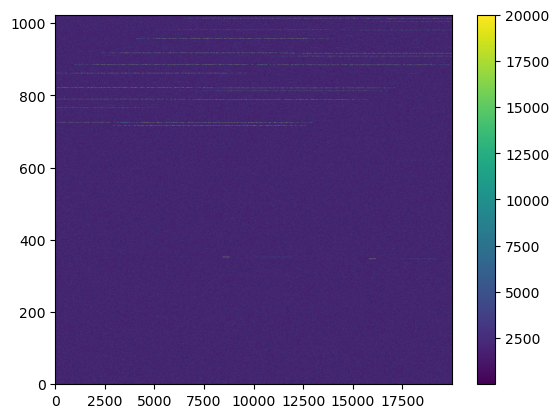

In [79]:
plt.imshow(power[:, 40000:60000], aspect='auto', origin='lower', vmax=20000)
plt.colorbar()
plt.show()

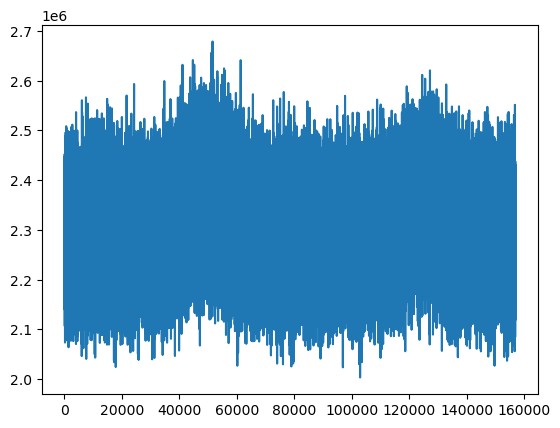

In [78]:
plt.plot(incoho_sum)

### Intelsat 33E debris